# TFM MIAX · 01 — Réplica del S&P 500 con cardinalidad restringida
### Baselines clásicos · Greedy + QP · MIQP · walk-forward mensual · comisiones

**Objetivo.** Comparar la calidad de réplica y el coste computacional de métodos clásicos cuando solo podemos mantener **K activos** de un universo de **N candidatos**. Simulamos una cartera real: decisiones al **cierre del mes anterior**, operaciones a la **apertura de la primera sesión del mes**, conservación de títulos entre rebalanceos y comisión proporcional por compra y venta.

**Métodos:** (1) equiponderación de los K activos más correlacionados con el índice, (2) selección *greedy forward* + optimización cuadrática de pesos y (3) **MIQP exacto / acotado por tiempo** si existe un solver compatible. **No se mezclan universos ni fechas en las comparaciones.**

**Resultados:** tracking error bruto/neto, RMSE y sesgo de réplica, patrimonio acumulado, costes, turnover, número de posiciones, tiempos por optimización, error frente a K, tiempos frente a N y estado de resolución del MIQP (sin inventar gaps).

> **Alcance de este primer notebook:** solo comisiones de compraventa (sin spread, impacto de mercado, impuestos ni dividendos explícitos). La optimización **no penaliza comisiones**; estas se descuentan después, durante la simulación (método A).

## 0 · Preparación y decisiones metodológicas

1. **Datos de acciones:** `sp500_history.parquet`, con `assetid`, `date`, `in_sp500`, `open`, `close`, `volume` y `unadjusted_close`. `assetid` identifica el activo; no usamos `symbol` como clave única.
2. **Benchmark:** `^GSPC` descargado en cada ejecución con `yfinance`; no se guarda en Parquet. Es el índice **Price Return**.
3. **Advertencia crucial sobre ajustes:** el Parquet contiene `open` y `close` aparentemente ajustados, pero **no sabemos aún si incorporan dividendos**. El backtest supone que ambos están en la misma escala de ajuste, y compara contra `^GSPC` solo como **experimento preliminar**. Si `close` es *total-return adjusted*, el tracking error contra `^GSPC` no será estrictamente comparable. Se muestra un diagnóstico; **antes de presentar resultados definitivos hay que verificar el proveedor/metadatos o sustituir el benchmark por una serie Total Return consistente**.
4. **Evitar look-ahead:** el universo y las correlaciones/liquidez se calculan únicamente con información hasta el cierre previo a la compra. El universo elegible requiere pertenencia histórica al S&P 500 en esa fecha y cobertura completa de la ventana.
5. **Universo N:** los N activos elegibles con mayor **volumen monetario mediano de los últimos 60 días** (`unadjusted_close × volume`). Es un criterio reproducible y conocido *ex ante*, no una selección por rentabilidad futura.
6. **Entrenamiento:** últimas 252 rentabilidades diarias de cierre a cierre; benchmark y activos alineados en fechas. **Reoptimización:** mensual, pesos objetivo calculados al cierre y ejecutados en la apertura siguiente.
7. **Autofinanciación:** se venden y compran únicamente los importes necesarios; las comisiones se pagan del patrimonio. Las posiciones son cantidades de «acciones ajustadas» para valorar coherentemente la serie ajustada; esto **no reproduce literalmente el número de acciones reales** ante splits/dividendos y es otra limitación del prototipo.
8. **Objetivo común:** minimizar `mean((R @ w - y)**2)` con `sum(w)=1`, `w>=0`, `||w||₀<=K`. Para que el MIQP sea tratable se usan N y K pequeños en la comparación mensual; la escalabilidad de greedy se analiza por separado.

**Instalación en el entorno del notebook (una vez):** `%pip install pandas pyarrow yfinance scipy matplotlib cvxpy osqp pyscipopt` y reiniciar kernel. **SCIP es opcional:** si no está instalado o CVXPY no lo detecta, el notebook ejecuta los otros métodos y marca MIQP como no disponible; **nunca lo sustituye silenciosamente por una heurística**.

In [1]:
from pathlib import Path
from itertools import combinations
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display

try:
    import yfinance as yf
except ImportError as e:
    raise ImportError("Instala yfinance con %pip install yfinance y reinicia el kernel") from e
try:
    import cvxpy as cp
except ImportError:
    cp = None

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True})
print("Pandas:", pd.__version__)
print("CVXPY:", cp.__version__ if cp is not None else "no instalado")
print("Solvers CVXPY:", cp.installed_solvers() if cp is not None else [])

Pandas: 3.0.6
CVXPY: 1.9.3
Solvers CVXPY: ['CLARABEL', 'SCS', 'SCIP', 'SCIPY', 'HIGHS', 'OSQP']


In [2]:
# === CONFIGURACIÓN CENTRAL ===
PARQUET_PATH = Path(r"C:/Users/Miriamdbg/Desktop/MIAX/Datos/sp500_history.parquet")
if not PARQUET_PATH.exists():
    PARQUET_PATH = Path("/mnt/data/sp500_history.parquet")  # adjunto en este chat
if not PARQUET_PATH.exists():
    PARQUET_PATH = Path("sp500_history.parquet")  # misma carpeta que el notebook

START_TEST = "2025-01-01"
END_TEST = "2026-01-01"           # exclusivo
DOWNLOAD_START = "2023-01-01"
DOWNLOAD_END = "2026-02-01"      # exclusivo; datos hasta enero 2026
TRAIN_DAYS = 252
LIQUIDITY_DAYS = 60
INITIAL_CAPITAL = 100_000.0
COMMISSION = 0.001              # 10 pb sobre importe negociado, compra Y venta

# Comparación mensual homogénea: MIQP puede ser costoso, por eso N reducido.
N_MAIN = 12
K_MAIN = (3, 5, 8)
RUN_MIQP = True
MIQP_TIME_LIMIT_S = 8.0         # por fecha y cardinalidad; puede devolver subóptimo

# Experimento complementario greedy a escala mayor.
N_GREEDY_LARGE = 30
K_GREEDY_LARGE = (5, 10, 15, 20)
RUN_LARGE_BACKTEST = True

# Escalabilidad en una fecha: N creciente con K fijo; MIQP solo en N pequeños.
N_GRID = (10, 20, 30, 50)
K_SCALING = 5
MIQP_N_GRID = (8, 10, 12)

print("Archivo:", PARQUET_PATH)
assert PARQUET_PATH.exists(), "Corrige PARQUET_PATH antes de continuar"
assert 0 <= COMMISSION < 1
assert max(K_MAIN) <= N_MAIN

Archivo: C:\Users\Miriamdbg\Desktop\MIAX\Datos\sp500_history.parquet


## 1 · Carga y comprobaciones de calidad

Leemos solo columnas y fechas necesarias. Descargamos `^GSPC` **en memoria**; no generamos otro fichero de datos. Los precios de apertura/cierre ajustados deben ser positivos. Revisamos cobertura, composición histórica y ratios de ajuste; los avisos no equivalen a una validación del proveedor.

In [3]:
cols = ["date", "assetid", "symbol", "in_sp500", "open", "close", "volume", "unadjusted_close"]
raw = pd.read_parquet(PARQUET_PATH, columns=cols)
raw["date"] = pd.to_datetime(raw["date"])
raw = raw.loc[(raw.date >= DOWNLOAD_START) & (raw.date < DOWNLOAD_END)].copy()
raw = raw.sort_values(["date", "assetid"])
assert not raw.duplicated(["date", "assetid"]).any(), "Duplicados fecha/assetid"
assert (raw[["open", "close", "unadjusted_close"]] > 0).all().all(), "Precios no positivos"

idx = yf.download("^GSPC", start=DOWNLOAD_START, end=DOWNLOAD_END,
                  auto_adjust=False, multi_level_index=False, progress=False)
assert not idx.empty, "Yahoo no devolvió datos de ^GSPC. Revisa conexión y fechas."
idx.index = pd.to_datetime(idx.index).tz_localize(None).normalize()
idx = idx[["Open", "Close"]].rename(columns={"Open": "idx_open", "Close": "idx_close"})
idx = idx.dropna().sort_index()
idx["idx_ret"] = idx["idx_close"].pct_change(fill_method=None)

ratio = raw["close"] / raw["unadjusted_close"]
print(f"Acciones: {len(raw):,} filas; {raw.assetid.nunique()} activos; {raw.date.min().date()} → {raw.date.max().date()}")
print(f"Índice: {len(idx):,} sesiones; {idx.index.min().date()} → {idx.index.max().date()}")
print("Ratio close / unadjusted_close (cuantiles):")
display(ratio.quantile([0, .01, .5, .99, 1]).to_frame("ratio"))
print("MIQP disponible:", cp is not None and "SCIP" in cp.installed_solvers())
if cp is None or "SCIP" not in cp.installed_solvers():
    warnings.warn("SCIP no disponible: MIQP se marcará como no ejecutado. Instala cvxpy y pyscipopt.")

c:\Users\Miriamdbg\anaconda3\envs\env_1\Lib\site-packages\yfinance\scrapers\history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


Acciones: 513,188 filas; 678 activos; 2023-01-03 → 2026-01-30
Índice: 772 sesiones; 2023-01-03 → 2026-01-30
Ratio close / unadjusted_close (cuantiles):


,ratio
0.00,0.020000
0.01,0.200000
0.50,0.983200
0.99,1.000000
1.00,15.000001


MIQP disponible: True


In [4]:
# Construcción de paneles (fechas × assetid), para no repetir pivots en cada mes.
prices_close = raw.pivot(index="date", columns="assetid", values="close").reindex(idx.index)
prices_open = raw.pivot(index="date", columns="assetid", values="open").reindex(idx.index)
notional = raw.assign(dollar_volume=raw["unadjusted_close"] * raw["volume"]).pivot(
    index="date", columns="assetid", values="dollar_volume").reindex(idx.index)
membership = raw.pivot(index="date", columns="assetid", values="in_sp500").reindex(idx.index)
asset_returns = prices_close.pct_change(fill_method=None)

# Diagnóstico de movimientos extremos (no los eliminamos sin investigar).
extreme = (asset_returns.abs() > 0.5).sum().sum()
print("Rentabilidades diarias con |r| > 50%:", int(extreme))
print("Componentes S&P 500 (últimas 5 sesiones):")
display((membership == 1).sum(axis=1).tail().to_frame("n_componentes"))
print("⚠ Revisar fuente de ajustes antes de interpretar TE como resultado definitivo.")

Rentabilidades diarias con |r| > 50%: 397
Componentes S&P 500 (últimas 5 sesiones):


,n_componentes
Date,
2026-01-26,503
2026-01-27,503
2026-01-28,503
2026-01-29,503
2026-01-30,503


⚠ Revisar fuente de ajustes antes de interpretar TE como resultado definitivo.


## 2 · Fechas de decisión, universo y función objetivo

**Calendario sin fuga temporal.** Para cada mes de test buscamos su primera sesión bursátil `trade_day`; `decision_day` es la sesión inmediatamente anterior. En `decision_day` solo usamos 252 retornos ya observados y seleccionamos candidatos elegibles.

El filtrado de cobertura **no mira el futuro**. Exigimos observaciones completas de cierre en entrenamiento y precios disponibles al cierre de decisión. Para la ejecución, si faltara un precio de apertura, se detiene la simulación en lugar de sustituirlo por un precio futuro.

**Nota sobre cardinalidad:** usamos `<= K` en la formulación matemática; la cartera equiponderada y greedy seleccionan K activos y pueden asignar pesos prácticamente nulos. En MIQP se impone `sum(z) <= K` y `w_i <= z_i`.

In [5]:
def monthly_schedule(index, start, end):
    test_dates = index[(index >= pd.Timestamp(start)) & (index < pd.Timestamp(end))]
    first_days = test_dates.to_series().groupby(test_dates.to_period("M")).first()
    out = []
    for trade_day in first_days:
        pos = index.get_loc(trade_day)
        assert pos > 0
        out.append((index[pos - 1], trade_day))
    return out

schedule = monthly_schedule(idx.index, START_TEST, END_TEST)
display(pd.DataFrame(schedule, columns=["decision_close", "execution_open"]))
assert len(schedule) == 12, "Se esperaban 12 rebalanceos en 2025"


def get_training(decision_day, n_candidates, min_k=1):
    # 252 retornos: necesitamos 253 cierres y todas las fechas son <= decision_day.
    loc = idx.index.get_loc(decision_day)
    assert loc >= TRAIN_DAYS
    days = idx.index[loc - TRAIN_DAYS:loc + 1]
    y = idx.loc[days[1:], "idx_ret"].to_numpy(dtype=float)
    assert len(y) == TRAIN_DAYS and np.isfinite(y).all()
    eligible = membership.loc[decision_day].eq(1)
    complete = prices_close.loc[days].notna().all(axis=0)
    positive = prices_close.loc[days].gt(0).all(axis=0)
    liquid = notional.loc[idx.index[max(0, loc - LIQUIDITY_DAYS + 1):loc + 1]].median(axis=0)
    valid = eligible & complete & positive & liquid.notna() & (liquid > 0)
    ranked = liquid.loc[valid].sort_values(ascending=False)
    ids = ranked.index[:n_candidates].tolist()
    if len(ids) < max(n_candidates, min_k):
        raise ValueError(f"Solo {len(ids)} elegibles en {decision_day.date()} para N={n_candidates}")
    R = asset_returns.loc[days[1:], ids].to_numpy(dtype=float)
    if not np.isfinite(R).all():
        raise ValueError("Rentabilidades incompletas tras filtrar cobertura")
    return ids, R, y

ids_demo, R_demo, y_demo = get_training(schedule[0][0], N_MAIN)
print("Ventana de entrenamiento:", R_demo.shape, "| fecha decisión:", schedule[0][0].date())
print("Activos candidatos (assetid):", ids_demo)

,decision_close,execution_open
0,2024-12-31,2025-01-02
1,2025-01-31,2025-02-03
2,2025-02-28,2025-03-03
3,2025-03-31,2025-04-01
4,2025-04-30,2025-05-01
5,2025-05-30,2025-06-02
6,2025-06-30,2025-07-01
7,2025-07-31,2025-08-01
8,2025-08-29,2025-09-02
9,2025-09-30,2025-10-01


Ventana de entrenamiento: (252, 12) | fecha decisión: 2024-12-31
Activos candidatos (assetid): [505718, 146481, 126558, 136817, 134016, 129769, 618960, 638141, 147750, 144161, 2733190, 128830]


## 3 · Optimizadores clásicos

Minimizamos la **media de errores cuadráticos diarios** (MSE):

$$
L(w)=\frac{1}{T}\|Rw-y\|_2^2,
\qquad
\mathbf{1}^{\top}w=1,
\quad
w\geq 0,
\quad
\|w\|_0\leq K.
$$

- **Equiponderado:** elegimos K activos por mayor correlación positiva con el benchmark en entrenamiento y asignamos `1/K`. Es un baseline sencillo, **no un óptimo**.
- **Greedy + QP:** añadimos el activo que más reduce la MSE tras reoptimizar los pesos de los seleccionados; repetimos hasta K. El subproblema convexo se resuelve mediante SLSQP (QP cuadrático con simplex).
- **Regresión L0 exacta:** enumera todos los subconjuntos de K activos y, para cada uno, estima por mínimos cuadrados los pesos long-only que suman uno. Conserva el subconjunto con menor MSE. Es el óptimo global para `N=12` y no necesita CVXPY; su coste combinatorio impide usarlo con N grande.
- **MIQP:** selecciona y pondera conjuntamente con variables binarias. SCIP es un solver de programación mixta, **puede detenerse por tiempo**; solo llamaremos «óptima» a una solución con estado `optimal`. Los tiempos incluyen el proceso de resolución, no la preparación de datos.

**Criterio de justicia:** mismo `R`, `y`, `N`, `K` y restricciones para los tres. La correlación y la selección se recalculan solo con datos pasados.

In [6]:
def mse(R, y, w):
    return float(np.mean((R @ w - y) ** 2))


def simplex_qp(R, y):
    """QP convexa con restricciones long-only y suma de pesos 1."""
    n = R.shape[1]
    gram = (R.T @ R) / len(y)
    rhs = (R.T @ y) / len(y)
    def obj(w): return float(w @ gram @ w - 2 * rhs @ w + np.mean(y * y))
    def jac(w): return 2 * (gram @ w - rhs)
    result = minimize(obj, np.full(n, 1/n), jac=jac, method="SLSQP",
                      bounds=[(0., 1.)] * n,
                      constraints={"type": "eq", "fun": lambda w: w.sum() - 1,
                                   "jac": lambda w: np.ones_like(w)},
                      options={"maxiter": 400, "ftol": 1e-13})
    if not result.success and abs(result.x.sum()-1) > 1e-5:
        raise RuntimeError(f"QP falló: {result.message}")
    w = np.maximum(result.x, 0)
    w /= w.sum()
    return w


def equal_corr(R, y, k):
    scores = []
    for j in range(R.shape[1]):
        if np.std(R[:, j]) < 1e-12:
            scores.append(-np.inf)
        else:
            scores.append(float(np.corrcoef(R[:, j], y)[0, 1]))
    chosen = np.argsort(np.nan_to_num(scores, nan=-np.inf))[::-1][:k]
    w = np.zeros(R.shape[1]); w[chosen] = 1/k
    return w


def greedy_path(R, y, max_k):
    """Devuelve pesos optimizados para cada cardinalidad de 1 a max_k."""
    n = R.shape[1]
    chosen = []
    remaining = list(range(n))
    path = {}
    for k in range(1, max_k+1):
        best = None
        for j in remaining:
            cols = chosen + [j]
            small = simplex_qp(R[:, cols], y)
            loss = mse(R[:, cols], y, small)
            if best is None or loss < best[0]:
                best = (loss, j, small)
        chosen.append(best[1]); remaining.remove(best[1])
        full = np.zeros(n); full[chosen] = best[2]
        path[k] = full
    return path


def exact_l0_regression(R, y, k):
    """Regresión L0 exacta por best-subset selection, con w>=0 y sum(w)=1."""
    n = R.shape[1]
    if not 1 <= k <= n:
        raise ValueError(f"K debe estar entre 1 y {n}")
    best_loss, best_cols, best_small = np.inf, None, None
    for cols in combinations(range(n), k):
        cols = np.asarray(cols, dtype=int)
        small = simplex_qp(R[:, cols], y)
        loss = mse(R[:, cols], y, small)
        if loss < best_loss:
            best_loss, best_cols, best_small = loss, cols, small
    w = np.zeros(n)
    w[best_cols] = best_small
    return w


def miqp_scip(R, y, k, time_limit_s=8):
    """MIQP verdadero. Devuelve pesos, estado y tiempo; NO inventa solución si falla."""
    if cp is None or "SCIP" not in cp.installed_solvers():
        return None, "unavailable", np.nan
    n = R.shape[1]
    w = cp.Variable(n, nonneg=True)
    z = cp.Variable(n, boolean=True)
    # Factor de escala: multiplicar la MSE por 1e6 no altera el óptimo.
    objective = cp.Minimize(cp.sum_squares(R @ w - y) * (1e6 / len(y)))
    problem = cp.Problem(objective, [cp.sum(w) == 1, w <= z, cp.sum(z) <= k])
    t0 = time.perf_counter()
    try:
        problem.solve(solver="SCIP", verbose=False,
                      scip_params={"limits/time": float(time_limit_s)})
        elapsed = time.perf_counter() - t0
        if w.value is None:
            return None, str(problem.status), elapsed
        arr = np.maximum(np.asarray(w.value).ravel(), 0)
        if arr.sum() <= 0:
            return None, "invalid_weights", elapsed
        arr /= arr.sum()
        if np.count_nonzero(arr > 1e-5) > k or abs(arr.sum()-1) > 1e-5:
            return None, "invalid_cardinality", elapsed
        return arr, str(problem.status), elapsed
    except Exception as exc:
        elapsed = time.perf_counter() - t0
        warnings.warn(f"SCIP no resolvió el MIQP: {type(exc).__name__}: {exc}")
        return None, "solver_error", elapsed

# Prueba unitaria sobre el primer entrenamiento
for k in K_MAIN:
    w_eq = equal_corr(R_demo, y_demo, k)
    w_gr = greedy_path(R_demo, y_demo, k)[k]
    assert abs(w_eq.sum()-1) < 1e-8 and abs(w_gr.sum()-1) < 1e-8
    assert (w_gr >= 0).all() and np.count_nonzero(w_gr > 1e-5) <= k
    print(f"K={k:2d} | MSE equiponderado={mse(R_demo,y_demo,w_eq):.8f} | greedy={mse(R_demo,y_demo,w_gr):.8f}")

K= 3 | MSE equiponderado=0.00014416 | greedy=0.00003644
K= 5 | MSE equiponderado=0.00012360 | greedy=0.00002750
K= 8 | MSE equiponderado=0.00007972 | greedy=0.00002521


## 4 · Reoptimización mensual y órdenes al día siguiente

**Método A:** el optimizador no conoce las comisiones. El motor de cartera sí conoce la cartera existente y solo compra/vende la **diferencia** respecto a los nuevos pesos.

La orden se ejecuta a la **apertura** de la siguiente sesión. Para calcular los títulos comprados resolvemos el presupuesto de manera autoconsistente:

\\[V_{\\mathrm{post}}=V_{\\mathrm{pre}}-c\\sum_i\\left|w_i^{*}V_{\\mathrm{post}}-q_i P_{i,\\mathrm{open}}\\right|.\\]

Así, **las comisiones iniciales y de cada rebalanceo se pagan con el propio capital**. En las fechas posteriores las cantidades se mantienen constantes; los pesos derivan con los precios. Una segunda cartera «bruta» ejecuta las **mismas decisiones** sin comisión, para aislar el coste de transacción.

**Valoración:** cartera a cierre diario; benchmark normalizado desde la **apertura del primer día** (evita comparar una compra a apertura con el índice desde el cierre anterior). En rebalanceos posteriores se capturan los movimientos nocturnos de ambos desde el cierre previo.

In [7]:
def execute_targets(holdings, cash, target, open_prices, fee_rate):
    """Vende/compra para alcanzar los pesos objetivo; autofinanciado, sin crédito."""
    ids = sorted(set(holdings) | set(target))
    p = np.array([open_prices[i] for i in ids], dtype=float)
    assert np.isfinite(p).all() and (p > 0).all(), "Aperturas inválidas"
    old_q = np.array([holdings.get(i, 0.) for i in ids])
    old_v = old_q * p
    pre = float(old_v.sum() + cash)
    assert pre > 0
    wt = np.array([target.get(i, 0.) for i in ids])
    assert (wt >= -1e-8).all() and abs(wt.sum()-1) < 1e-7
    if fee_rate == 0:
        post = pre
    else:
        lo, hi = 0., pre
        for _ in range(65):
            mid = (lo + hi) / 2
            traded = np.abs(wt * mid - old_v).sum()
            if mid + fee_rate * traded > pre:
                hi = mid
            else:
                lo = mid
        post = (lo + hi) / 2
    new_v = wt * post
    traded = float(np.abs(new_v - old_v).sum())
    fees = fee_rate * traded
    new_q = {i: float(v / price) for i, v, price in zip(ids, new_v, p) if v > 1e-9}
    new_cash = float(pre - fees - new_v.sum())
    assert new_cash > -1e-6 * pre, "No hay efectivo suficiente"
    return new_q, max(new_cash, 0.), fees, traded, pre


def value_at_close(holdings, cash, date):
    if not holdings:
        return float(cash)
    p = prices_close.loc[date, list(holdings)]
    if p.isna().any():
        missing = p.index[p.isna()].tolist()
        raise ValueError(f"Faltan precios al cierre de {date.date()} para {missing}; revisar exclusiones/delisting")
    return float(cash + sum(holdings[i] * float(p[i]) for i in holdings))


def build_targets(n_candidates, k_values, include_miqp=True, include_l0=False):
    """Optimiza solo en fechas de decisión. Devuelve órdenes objetivo y tiempos."""
    targets, logs = {}, []
    for decision, trade in schedule:
        ids, R, y = get_training(decision, n_candidates)
        max_k = max(k_values)
        t0 = time.perf_counter()
        path = greedy_path(R, y, max_k)
        greedy_total = time.perf_counter() - t0
        # Un único path greedy da resultados para todos los K: coste compartido.
        for k in k_values:
            t0 = time.perf_counter()
            w_eq = equal_corr(R, y, k)
            eq_time = time.perf_counter()-t0
            if include_l0:
                t0 = time.perf_counter()
                w_l0 = exact_l0_regression(R, y, k)
                l0_time = time.perf_counter() - t0
            else:
                w_l0, l0_time = None, np.nan
            for method, w, seconds, status in [
                ("EqualCorr", w_eq, eq_time, "baseline"),
                ("GreedyQP", path[k], greedy_total, "heuristic")]:
                targets[(trade, method, k)] = {i: float(x) for i, x in zip(ids, w) if x > 1e-9}
                logs.append(dict(decision=decision, trade=trade, method=method, N=n_candidates,
                                 K=k, seconds=seconds, train_mse=mse(R,y,w), status=status,
                                 active=int(np.count_nonzero(w > 1e-5))))
            if w_l0 is not None:
                targets[(trade, "RegresionL0", k)] = {i: float(x) for i, x in zip(ids, w_l0) if x > 1e-9}
                logs.append(dict(decision=decision, trade=trade, method="RegresionL0", N=n_candidates,
                                 K=k, seconds=l0_time, train_mse=mse(R,y,w_l0), status="optimal",
                                 active=int(np.count_nonzero(w_l0 > 1e-5))))
            if include_miqp:
                w, status, seconds = miqp_scip(R, y, k, MIQP_TIME_LIMIT_S)
                if w is not None:
                    targets[(trade, "MIQP", k)] = {i: float(x) for i, x in zip(ids, w) if x > 1e-9}
                logs.append(dict(decision=decision, trade=trade, method="MIQP", N=n_candidates,
                                 K=k, seconds=seconds, train_mse=mse(R,y,w) if w is not None else np.nan,
                                 status=status, active=int(np.count_nonzero(w > 1e-5)) if w is not None else 0))
        print(f"{decision.date()} → {trade.date()} | N={n_candidates} | greedy path: {greedy_total:.2f}s")
    return targets, pd.DataFrame(logs)


def simulate(targets, method, k):
    """Devuelve NAV bruto/neto diario y registros de operaciones."""
    needed = [(d,t) for d,t in schedule if (t, method, k) in targets]
    if len(needed) != len(schedule):
        return None, None   # no ocultar meses sin solución MIQP
    holdings = {"net": {}, "gross": {}}
    cash = {"net": INITIAL_CAPITAL, "gross": INITIAL_CAPITAL}
    nav, orders = [], []
    first_trade = needed[0][1]
    first_open_idx = float(idx.loc[first_trade, "idx_open"])
    if not np.isfinite(first_open_idx) or first_open_idx <= 0:
        raise ValueError("Benchmark sin apertura inicial")
    trade_map = {t: d for d,t in needed}
    test_days = idx.index[(idx.index >= first_trade) & (idx.index < pd.Timestamp(END_TEST))]
    for day in test_days:
        if day in trade_map:
            target = targets[(day, method, k)]
            required = sorted(set(target) | set(holdings["net"]) | set(holdings["gross"]))
            op = prices_open.loc[day, required]
            if op.isna().any():
                raise ValueError(f"Faltan aperturas el {day.date()} para {op.index[op.isna()].tolist()}")
            opening = op.to_dict()
            net_result = execute_targets(holdings["net"], cash["net"], target, opening, COMMISSION)
            gross_result = execute_targets(holdings["gross"], cash["gross"], target, opening, 0.)
            holdings["net"], cash["net"], fee, traded, pre = net_result
            holdings["gross"], cash["gross"] = gross_result[:2]
            orders.append(dict(date=day, method=method, K=k, fee=fee,
                               traded=traded, turnover=traded/pre, active=len(target),
                               nav_pre=pre, nav_post=pre-fee))
        net = value_at_close(holdings["net"], cash["net"], day)
        gross = value_at_close(holdings["gross"], cash["gross"], day)
        bench = INITIAL_CAPITAL * float(idx.loc[day, "idx_close"]) / first_open_idx
        nav.append(dict(date=day, method=method, K=k, net=net, gross=gross, benchmark=bench))
    return pd.DataFrame(nav).set_index("date"), pd.DataFrame(orders)


def summarize_nav(nav, orders, method, k, n):
    # Primer día: rentabilidad apertura→cierre; siguientes días: cierre→cierre.
    rel = nav[["net", "gross", "benchmark"]] / INITIAL_CAPITAL
    r = rel.pct_change(fill_method=None)
    r.iloc[0] = rel.iloc[0] - 1
    active_net = r["net"] - r["benchmark"]
    active_gross = r["gross"] - r["benchmark"]
    return dict(method=method, N=n, K=k,
                TE_net=active_net.std(ddof=1) * np.sqrt(252),
                TE_gross=active_gross.std(ddof=1) * np.sqrt(252),
                RMSE_net=np.sqrt(np.mean(active_net**2)) * np.sqrt(252),
                bias_ann=active_net.mean() * 252,
                return_net=rel["net"].iloc[-1]-1,
                return_gross=rel["gross"].iloc[-1]-1,
                return_index=rel["benchmark"].iloc[-1]-1,
                fees_eur=orders["fee"].sum(),
                fees_pct_initial=orders["fee"].sum()/INITIAL_CAPITAL,
                turnover_total=orders["turnover"].sum(),
                trades=len(orders), avg_positions=orders["active"].mean())

# Prueba de autofinanciación: 100.000 € → compra con comisiones sin saldo negativo
q, cash_test, fee_test, traded_test, pre_test = execute_targets(
    {}, INITIAL_CAPITAL, {101: .6, 102: .4}, {101: 100., 102: 50.}, COMMISSION)
assert cash_test < 1e-5 and abs(pre_test - fee_test - sum(q[i]*{101:100.,102:50.}[i] for i in q)) < 1e-4
print(f"Test contable OK | comisión inicial: {fee_test:.2f} € | efectivo: {cash_test:.6f} €")

Test contable OK | comisión inicial: 99.90 € | efectivo: 0.000000 €


## 5 · Experimento principal: tres métodos, mismas fechas, N y K

**Atención al tiempo:** el MIQP puede necesitar hasta `12 meses × 3 cardinalidades × 8 s ≈ 288 s` de solver, además de la sobrecarga. Si no existe SCIP o no se obtiene solución factible en algún mes, ese backtest MIQP se identifica como **incompleto** y no se calcula su resultado anual. No se rellenan huecos con soluciones de otro método.

**Interpretación de tiempos greedy:** para obtener varios K se construye una única trayectoria incremental; el tiempo registrado para cada K es el **tiempo total de esa trayectoria hasta `max(K_MAIN)`**, compartido entre los K, no tiempos independientes. Para medir escalabilidad por K, más abajo se mide por separado.

In [8]:
targets_main, log_main = build_targets(N_MAIN, K_MAIN, include_miqp=RUN_MIQP, include_l0=True)
print("Estados MIQP:")
display(log_main.loc[log_main.method == "MIQP"].groupby(["K", "status"]).size().rename("meses").to_frame())

nav_main, orders_main, rows_main = {}, {}, []
for method in ("EqualCorr", "GreedyQP", "RegresionL0", "MIQP"):
    for k in K_MAIN:
        result = simulate(targets_main, method, k)
        if result[0] is None:
            print(f"Sin backtest anual completo: {method}, K={k}")
            continue
        nav_main[(method,k)], orders_main[(method,k)] = result
        rows_main.append(summarize_nav(*result, method, k, N_MAIN))
summary_main = pd.DataFrame(rows_main).sort_values(["K", "method"])
show_cols = ["method", "N", "K", "TE_net", "TE_gross", "RMSE_net", "bias_ann",
             "return_net", "return_index", "fees_eur", "turnover_total"]
display(summary_main[show_cols].style.format({
    "TE_net":"{:.2%}","TE_gross":"{:.2%}","RMSE_net":"{:.2%}",
    "bias_ann":"{:.2%}","return_net":"{:.2%}","return_index":"{:.2%}",
    "fees_eur":"{:,.2f}","turnover_total":"{:.2f}"}))

2024-12-31 → 2025-01-02 | N=12 | greedy path: 0.07s
2025-01-31 → 2025-02-03 | N=12 | greedy path: 0.08s
2025-02-28 → 2025-03-03 | N=12 | greedy path: 0.08s
2025-03-31 → 2025-04-01 | N=12 | greedy path: 0.07s
2025-04-30 → 2025-05-01 | N=12 | greedy path: 0.07s
2025-05-30 → 2025-06-02 | N=12 | greedy path: 0.07s
2025-06-30 → 2025-07-01 | N=12 | greedy path: 0.07s
2025-07-31 → 2025-08-01 | N=12 | greedy path: 0.08s
2025-08-29 → 2025-09-02 | N=12 | greedy path: 0.08s
2025-09-30 → 2025-10-01 | N=12 | greedy path: 0.08s
2025-10-31 → 2025-11-03 | N=12 | greedy path: 0.08s
2025-11-28 → 2025-12-01 | N=12 | greedy path: 0.08s
Estados MIQP:


,,meses
K,status,
3,optimal,12
5,optimal,12
8,optimal,12


,method,N,K,TE_net,TE_gross,RMSE_net,bias_ann,return_net,return_index,fees_eur,turnover_total
0,EqualCorr,12,3,17.42%,17.45%,17.39%,-0.93%,11.71%,15.96%,553.63,5.38
3,GreedyQP,12,3,12.30%,12.28%,12.31%,15.15%,34.83%,15.96%,502.42,4.23
9,MIQP,12,3,12.98%,12.93%,12.98%,11.17%,29.42%,15.96%,696.90,6.02
6,RegresionL0,12,3,12.98%,12.93%,12.97%,11.17%,29.42%,15.96%,696.51,6.01
1,EqualCorr,12,5,16.04%,16.05%,16.01%,0.17%,13.16%,15.96%,349.06,3.51
4,GreedyQP,12,5,9.76%,9.74%,9.76%,8.53%,25.90%,15.96%,388.37,3.52
10,MIQP,12,5,9.76%,9.74%,9.76%,8.54%,25.91%,15.96%,388.89,3.52
7,RegresionL0,12,5,9.76%,9.74%,9.76%,8.53%,25.90%,15.96%,388.37,3.52
2,EqualCorr,12,8,15.99%,15.98%,15.96%,5.30%,18.77%,15.96%,378.01,3.65
5,GreedyQP,12,8,9.29%,9.28%,9.29%,9.30%,26.86%,15.96%,353.15,3.25


### 5.1 · ¿Cómo de bien replica cada método?

El **tracking error (TE)** es la desviación estándar anualizada de las rentabilidades activas diarias. **No detecta por sí solo un sesgo constante**, por eso mostramos también RMSE anualizada y sesgo anualizado. TE y RMSE **no son intercambiables**. La rentabilidad neta refleja las comisiones pagadas en la apertura de cada rebalanceo.

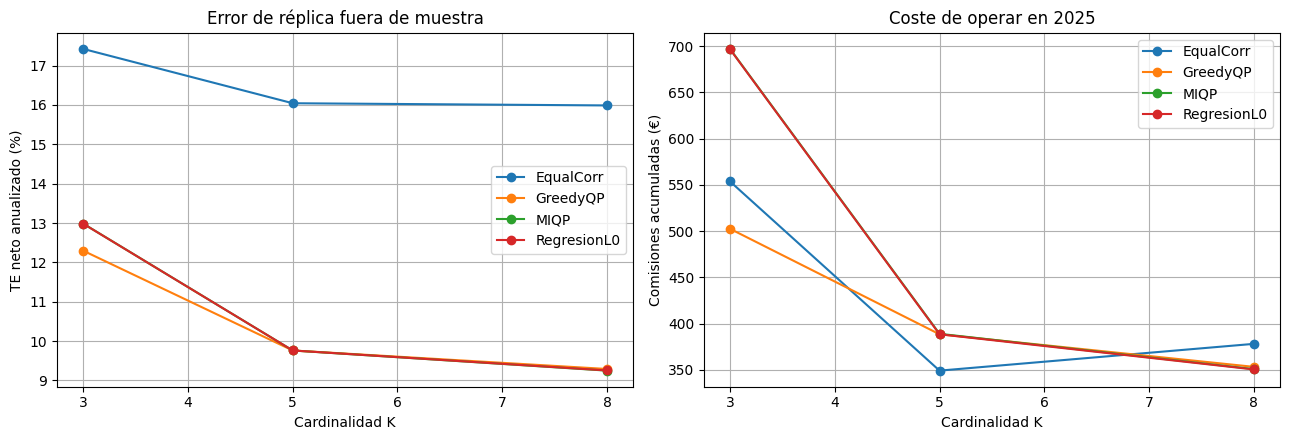

In [9]:
if not summary_main.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for method, g in summary_main.groupby("method"):
        g = g.sort_values("K")
        axes[0].plot(g.K, g.TE_net * 100, marker="o", label=method)
        axes[1].plot(g.K, g.fees_eur, marker="o", label=method)
    axes[0].set(xlabel="Cardinalidad K", ylabel="TE neto anualizado (%)", title="Error de réplica fuera de muestra")
    axes[1].set(xlabel="Cardinalidad K", ylabel="Comisiones acumuladas (€)", title="Coste de operar en 2025")
    axes[0].legend(); axes[1].legend()
    plt.tight_layout(); plt.show()

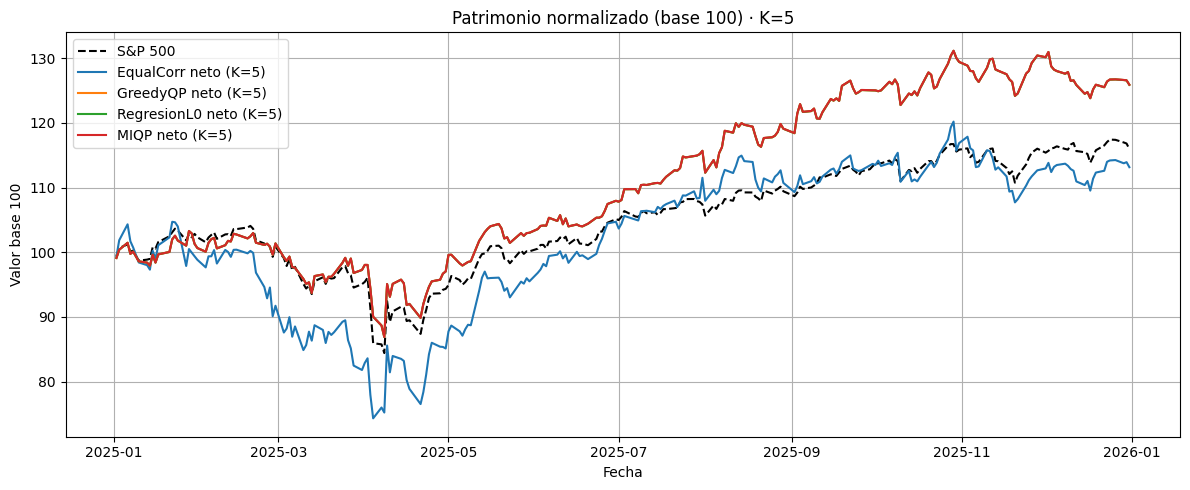

In [10]:
# Evolución del capital de todos los métodos para un K comparable
K_PLOT = 5
fig, ax = plt.subplots(figsize=(12, 5))
first = next(iter(nav_main.values()), None)
if first is not None:
    ax.plot(first.index, first["benchmark"] / INITIAL_CAPITAL * 100, "k--", label="S&P 500")
for (method,k), nav in nav_main.items():
    if k == K_PLOT:
        ax.plot(nav.index, nav["net"] / INITIAL_CAPITAL * 100, label=f"{method} neto (K={k})")
ax.set(title=f"Patrimonio normalizado (base 100) · K={K_PLOT}", ylabel="Valor base 100", xlabel="Fecha")
ax.legend(); plt.tight_layout(); plt.show()

### 5.2 · ¿Cómo evoluciona el error mes a mes?

Calculamos el TE sobre los retornos diarios **de cada mes**, usando el mismo punto de partida y las mismas decisiones de ejecución. Con ~20 observaciones mensuales es una estimación ruidosa: sirve para observar variabilidad, no para afirmar significación estadística.

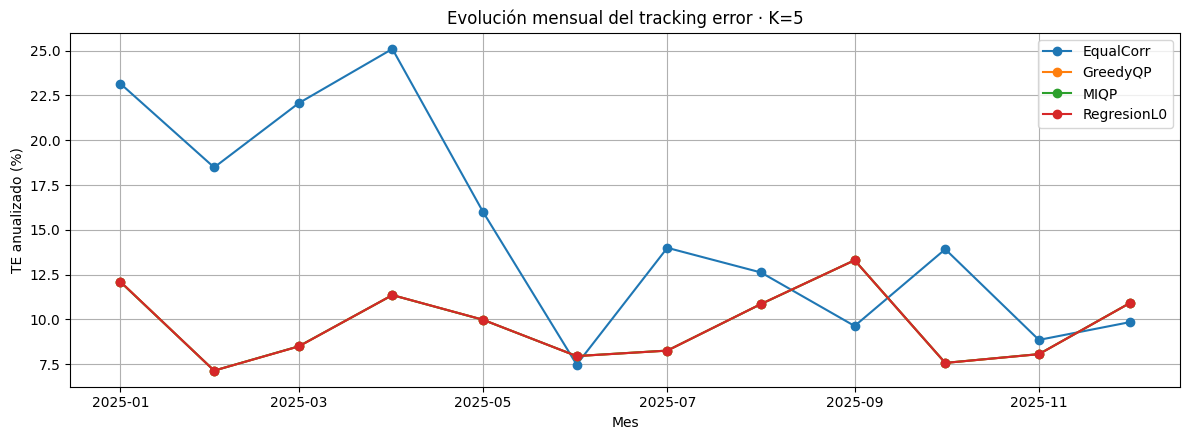

In [11]:
monthly_rows = []
for (method,k), nav in nav_main.items():
    ret = (nav[["net", "benchmark"]] / INITIAL_CAPITAL).pct_change(fill_method=None)
    ret.iloc[0] = nav[["net", "benchmark"]].iloc[0] / INITIAL_CAPITAL - 1
    active = ret["net"] - ret["benchmark"]
    for period, x in active.groupby(active.index.to_period("M")):
        monthly_rows.append(dict(month=period.to_timestamp(), method=method, K=k,
                                 TE_month=x.std(ddof=1)*np.sqrt(252),
                                 RMSE_month=np.sqrt(np.mean(x*x))*np.sqrt(252)))
monthly_error = pd.DataFrame(monthly_rows)
fig, ax = plt.subplots(figsize=(12, 4.5))
if not monthly_error.empty:
    for method, g in monthly_error.loc[monthly_error.K == K_PLOT].groupby("method"):
        ax.plot(g.month, g.TE_month*100, marker="o", label=method)
ax.set(title=f"Evolución mensual del tracking error · K={K_PLOT}", ylabel="TE anualizado (%)", xlabel="Mes")
ax.legend(); plt.tight_layout(); plt.show()

### 5.3 · Tiempo por rebalanceo y error de entrenamiento

La tabla muestra los tiempos medidos del optimizador (no incluye descarga, carga, selección de candidatos ni simulación de órdenes). El MIQP puede ser **óptimo, factible subóptimo, no resuelto o no disponible**: revisar `status` antes de compararlo. No inferimos *optimality gap* cuando CVXPY/SCIP no lo expone de forma fiable; se informa el estado y el límite temporal.

,method,N,K,mean_seconds,max_seconds,mean_train_mse,solved_months
0,EqualCorr,12,3,0.001,0.002,0.000109935,12
1,EqualCorr,12,5,0.001,0.002,0.000110037,12
2,EqualCorr,12,8,0.001,0.001,0.000120557,12
3,GreedyQP,12,3,0.076,0.081,0.000046778,12
4,GreedyQP,12,5,0.076,0.081,0.000034706,12
5,GreedyQP,12,8,0.076,0.081,0.000031981,12
6,MIQP,12,3,2.129,2.950,0.000046425,12
7,MIQP,12,5,1.981,3.246,0.000034706,12
8,MIQP,12,8,1.740,3.203,0.000031981,12
9,RegresionL0,12,3,0.177,0.188,0.000046425,12


,decision,method,N,K,seconds,train_mse,status
0,2024-12-31,EqualCorr,12,3,0.000682,0.000144,baseline
1,2024-12-31,GreedyQP,12,3,0.074730,0.000036,heuristic
2,2024-12-31,RegresionL0,12,3,0.171641,0.000036,optimal
3,2024-12-31,MIQP,12,3,2.051124,0.000036,optimal
4,2024-12-31,EqualCorr,12,5,0.001506,0.000124,baseline
5,2024-12-31,GreedyQP,12,5,0.074730,0.000027,heuristic
6,2024-12-31,RegresionL0,12,5,1.141084,0.000027,optimal
7,2024-12-31,MIQP,12,5,1.999712,0.000027,optimal
8,2024-12-31,EqualCorr,12,8,0.000849,0.000080,baseline
9,2024-12-31,GreedyQP,12,8,0.074730,0.000025,heuristic


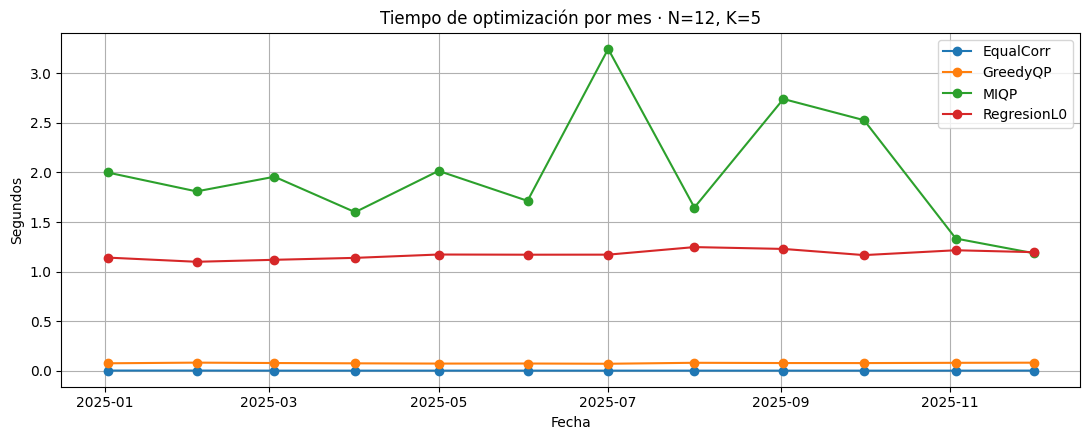

In [12]:
timing_summary = log_main.groupby(["method", "N", "K"], as_index=False).agg(
    mean_seconds=("seconds", "mean"), max_seconds=("seconds", "max"),
    mean_train_mse=("train_mse", "mean"), solved_months=("train_mse", "count"))
display(timing_summary.style.format({"mean_seconds":"{:.3f}", "max_seconds":"{:.3f}", "mean_train_mse":"{:.9f}"}))
display(log_main[["decision", "method", "N", "K", "seconds", "train_mse", "status"]].head(18))
fig, ax = plt.subplots(figsize=(11,4.5))
for method, g in log_main.loc[log_main.K == K_PLOT].groupby("method"):
    ax.plot(g.trade, g.seconds, marker="o", label=method)
ax.set(title=f"Tiempo de optimización por mes · N={N_MAIN}, K={K_PLOT}", ylabel="Segundos", xlabel="Fecha")
ax.legend(); plt.tight_layout(); plt.show()

## 6 · Experimento adicional: greedy con 30 candidatos

El MIQP para `N=30, K=20` puede resultar demasiado costoso en un portátil. Por ello separamos **la comparación justa de métodos** (`N=12`) de un **experimento de escalabilidad financiera** de greedy (`N=30`). **No se comparan directamente las métricas entre universos distintos como si fuesen el mismo problema.**

2024-12-31 → 2025-01-02 | N=30 | greedy path: 1.18s
2025-01-31 → 2025-02-03 | N=30 | greedy path: 1.14s
2025-02-28 → 2025-03-03 | N=30 | greedy path: 1.12s
2025-03-31 → 2025-04-01 | N=30 | greedy path: 1.02s
2025-04-30 → 2025-05-01 | N=30 | greedy path: 0.99s
2025-05-30 → 2025-06-02 | N=30 | greedy path: 1.07s
2025-06-30 → 2025-07-01 | N=30 | greedy path: 0.95s
2025-07-31 → 2025-08-01 | N=30 | greedy path: 0.99s
2025-08-29 → 2025-09-02 | N=30 | greedy path: 0.93s
2025-09-30 → 2025-10-01 | N=30 | greedy path: 1.12s
2025-10-31 → 2025-11-03 | N=30 | greedy path: 1.02s
2025-11-28 → 2025-12-01 | N=30 | greedy path: 1.01s


,method,N,K,TE_net,TE_gross,fees_eur,turnover_total,return_net
0,EqualCorr,30,5,19.46%,19.47%,454.21,4.65,12.14%
1,EqualCorr,30,10,15.97%,15.97%,498.79,4.79,25.02%
2,EqualCorr,30,15,13.80%,13.80%,397.65,3.87,34.85%
3,EqualCorr,30,20,13.10%,13.10%,360.62,3.40,36.82%
4,GreedyQP,30,5,8.26%,8.28%,843.96,7.35,33.86%
5,GreedyQP,30,10,5.45%,5.46%,747.26,6.88,28.87%
6,GreedyQP,30,15,4.74%,4.74%,546.37,5.21,24.25%
7,GreedyQP,30,20,4.15%,4.15%,376.71,3.60,22.90%


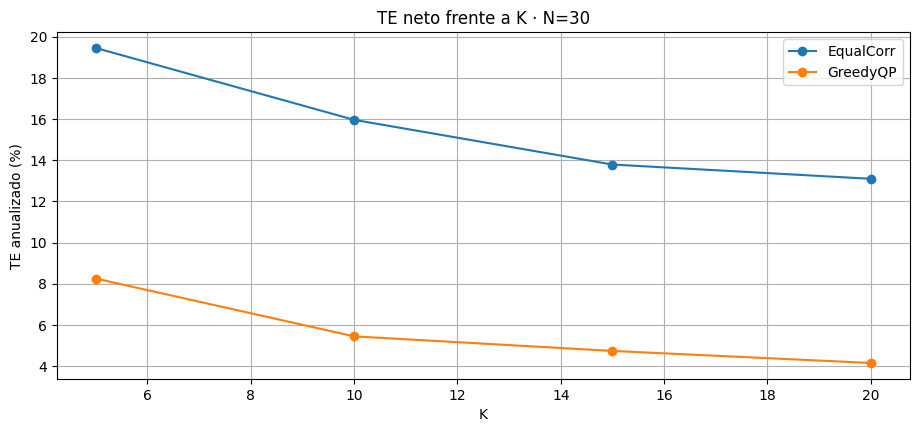

In [13]:
summary_large = pd.DataFrame()
log_large = pd.DataFrame()
nav_large = {}
if RUN_LARGE_BACKTEST:
    targets_large, log_large = build_targets(N_GREEDY_LARGE, K_GREEDY_LARGE, include_miqp=False)
    rows_large = []
    for method in ("EqualCorr", "GreedyQP"):
        for k in K_GREEDY_LARGE:
            nav, orders = simulate(targets_large, method, k)
            nav_large[(method,k)] = nav
            rows_large.append(summarize_nav(nav, orders, method, k, N_GREEDY_LARGE))
    summary_large = pd.DataFrame(rows_large)
    display(summary_large[["method","N","K","TE_net","TE_gross","fees_eur","turnover_total","return_net"]].style.format({
        "TE_net":"{:.2%}","TE_gross":"{:.2%}","fees_eur":"{:,.2f}",
        "turnover_total":"{:.2f}","return_net":"{:.2%}"}))
    fig, ax = plt.subplots()
    for method,g in summary_large.groupby("method"):
        ax.plot(g.K, 100*g.TE_net, marker="o", label=method)
    ax.set(title="TE neto frente a K · N=30", xlabel="K", ylabel="TE anualizado (%)")
    ax.legend(); plt.show()

## 7 · Escalabilidad: ¿cómo cambian el error y el tiempo al crecer N y K?

**Medición controlada en una sola fecha de decisión** (último cierre de 2024), sobre los mismos 252 retornos. El tiempo de greedy incluye construir el camino hasta K; se ejecuta **de nuevo** para cada par `(N,K)` y por tanto **sí es comparable por K**. Se muestran tanto error de entrenamiento como tiempo: el error fuera de muestra ya se evaluó en el backtest mensual.

Para MIQP probamos solo `N=8,10,12`, `K=5` y límite temporal; su tiempo no debe interpretarse como complejidad asintótica si alcanza el *timeout*.

,method,N,K,seconds,train_mse,status
0,GreedyQP,10,3,0.022,0.000036436,heuristic
1,GreedyQP,10,5,0.040,0.000027497,heuristic
2,GreedyQP,10,10,0.062,0.000025295,heuristic
3,GreedyQP,20,3,0.031,0.000026397,heuristic
4,GreedyQP,20,5,0.079,0.000015928,heuristic
5,GreedyQP,20,10,0.210,0.000010014,heuristic
6,GreedyQP,20,15,0.359,0.000009055,heuristic
7,GreedyQP,20,20,0.478,0.000008950,heuristic
8,GreedyQP,30,3,0.046,0.000018603,heuristic
9,GreedyQP,30,5,0.115,0.000012573,heuristic


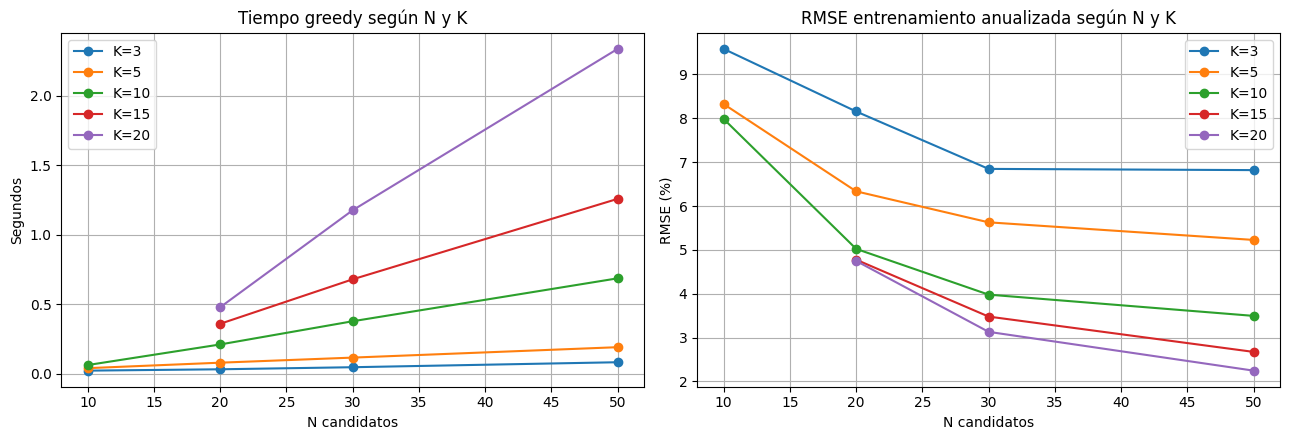

,N,K,seconds,train_mse,status
18,8,5,1.841166,0.000044,optimal
19,10,5,1.080706,0.000027,optimal
20,12,5,1.894340,0.000027,optimal


In [14]:
scaling_rows = []
decision = schedule[0][0]
for N in N_GRID:
    ids, R, y = get_training(decision, N)
    for k in [x for x in (3, 5, 10, 15, 20) if x <= N]:
        t0 = time.perf_counter()
        w = greedy_path(R, y, k)[k]
        seconds = time.perf_counter()-t0
        scaling_rows.append(dict(method="GreedyQP", N=N, K=k,
                                 seconds=seconds, train_mse=mse(R,y,w), status="heuristic"))
for N in MIQP_N_GRID if RUN_MIQP else ():
    ids, R, y = get_training(decision, N)
    k = min(K_SCALING, N)
    w, status, seconds = miqp_scip(R, y, k, MIQP_TIME_LIMIT_S)
    scaling_rows.append(dict(method="MIQP", N=N, K=k, seconds=seconds,
                             train_mse=mse(R,y,w) if w is not None else np.nan, status=status))
scaling = pd.DataFrame(scaling_rows)
display(scaling.style.format({"seconds":"{:.3f}","train_mse":"{:.9f}"}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k, g in scaling.loc[scaling.method == "GreedyQP"].groupby("K"):
    axes[0].plot(g.N, g.seconds, marker="o", label=f"K={k}")
    axes[1].plot(g.N, np.sqrt(g.train_mse)*np.sqrt(252)*100, marker="o", label=f"K={k}")
axes[0].set(title="Tiempo greedy según N y K", xlabel="N candidatos", ylabel="Segundos")
axes[1].set(title="RMSE entrenamiento anualizada según N y K", xlabel="N candidatos", ylabel="RMSE (%)")
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()

miqp_scale = scaling.loc[scaling.method == "MIQP"]
if not miqp_scale.empty:
    display(miqp_scale[["N","K","seconds","train_mse","status"]])

## 8 · Controles de validez y limitaciones

**Controles implementados:** claves únicas fecha-activo, no anticipación temporal en la selección, pertenencia histórica, ventana de entrenamiento completa, misma muestra para métodos, presupuesto autofinanciado, comisiones en compra inicial y rebalanceos, posiciones mantenidas sin reoptimización intrames, MIQP no sustituido por heurística, y backtest MIQP incompleto no presentado como anual.

**Limitaciones que deben documentarse en el TFM:**

1. **Ajustes y dividendos:** `^GSPC` es Price Return; el ajuste de `close`/`open` debe confirmarse. Si las acciones incluyen dividendos, cambiar a índice Total Return compatible. No afirmar que el error reportado es definitivo hasta resolverlo.
2. **Aperturas ajustadas:** usamos cantidades sintéticas de acciones ajustadas; para una simulación operacional literal con títulos reales, habría que gestionar splits/dividendos y ejecutar con precios no ajustados, manteniendo un libro de eventos corporativos.
3. **Delistings y huecos:** si desaparece un activo en test, el motor **se detiene** y pide tratamiento explícito (liquidación, delisting return, etc.); no rellena con precios futuros. Esto puede ocurrir al extender el periodo.
4. **Sesgo de disponibilidad de información:** `in_sp500` se trata como pertenencia histórica fiable, pero hay que confirmar su origen y disponibilidad a la fecha.
5. **Costes:** comisión plana 10 pb; sin spread, slippage, market impact, impuestos, interés de caja, restricciones de lotes ni costes de custodia.
6. **MIQP:** estados `optimal_inaccurate`/`user_limit` no equivalen a prueba de optimalidad. No se publica gap si el solver no proporciona una cota verificable. Para un estudio formal, registrar cota primal/dual y gap directamente desde SCIP.
7. **Comparación de tiempos:** los tiempos dependen del hardware, solver y configuración; repetir experimentos y registrar entorno para conclusiones sólidas.
8. **Greedy:** al construir un camino hasta K máximo, el tiempo compartido del experimento mensual **no es tiempo incremental por K**; el experimento de escalabilidad sí mide el tiempo por K de forma separada.
9. **Métrica:** TE anualizada mide dispersión de diferencias de retornos; RMSE incluye sesgo. Los costes pueden producir sesgo aunque TE apenas cambie.

**Siguientes extensiones, fuera del alcance de este notebook:** optimización con comisiones en el objetivo (método B), restricciones sectoriales, QUBO/QAOA, discretización de pesos, análisis por varios años y validación estadística de diferencias.

In [15]:
# Tabla de cierre: resumen reproducible, sin guardar el índice en disco.
print("CONFIGURACIÓN:", dict(N_MAIN=N_MAIN, K_MAIN=K_MAIN, train_days=TRAIN_DAYS,
                              commission=COMMISSION, rebalance="monthly", execution="next_open",
                              test=f"{START_TEST} → {END_TEST}"))
print("RESULTADOS PRINCIPALES:")
display(summary_main.sort_values(["K", "method"]) if not summary_main.empty else "Sin resultados completos")
print("MIQP status por mes:")
display(log_main.loc[log_main.method == "MIQP", ["trade", "K", "status", "seconds"]])
print("IMPORTANTE: validar la política de dividendos y ajustes del Parquet antes de publicar TE.")

CONFIGURACIÓN: {'N_MAIN': 12, 'K_MAIN': (3, 5, 8), 'train_days': 252, 'commission': 0.001, 'rebalance': 'monthly', 'execution': 'next_open', 'test': '2025-01-01 → 2026-01-01'}
RESULTADOS PRINCIPALES:


,method,N,K,TE_net,TE_gross,RMSE_net,bias_ann,return_net,return_gross,return_index,fees_eur,fees_pct_initial,turnover_total,trades,avg_positions
0,EqualCorr,12,3,0.174247,0.174536,0.173900,-0.009350,0.117090,0.123117,0.159614,553.626171,0.005536,5.379409,12,3.0
3,GreedyQP,12,3,0.122960,0.122850,0.123084,0.151489,0.348321,0.354037,0.159614,502.419834,0.005024,4.229520,12,3.0
9,MIQP,12,3,0.129839,0.129293,0.129770,0.111659,0.294220,0.302036,0.159614,696.896270,0.006969,6.017697,12,3.0
6,RegresionL0,12,3,0.129815,0.129269,0.129746,0.111671,0.294241,0.302052,0.159614,696.513037,0.006965,6.013553,12,3.0
1,EqualCorr,12,5,0.160439,0.160505,0.160118,0.001724,0.131587,0.135565,0.159614,349.058647,0.003491,3.508487,12,5.0
4,GreedyQP,12,5,0.097601,0.097438,0.097554,0.085298,0.258967,0.263402,0.159614,388.371990,0.003884,3.515196,12,5.0
10,MIQP,12,5,0.097598,0.097436,0.097552,0.085436,0.259143,0.263584,0.159614,388.885967,0.003889,3.519228,12,5.0
7,RegresionL0,12,5,0.097601,0.097438,0.097554,0.085298,0.258967,0.263402,0.159614,388.371990,0.003884,3.515196,12,5.0
2,EqualCorr,12,8,0.159883,0.159848,0.159598,0.053023,0.187719,0.192068,0.159614,378.009679,0.003780,3.654508,12,8.0
5,GreedyQP,12,8,0.092895,0.092822,0.092894,0.092955,0.268570,0.272707,0.159614,353.145138,0.003531,3.254819,12,8.0


MIQP status por mes:


,trade,K,status,seconds
3,2025-01-02,3,optimal,2.051124
7,2025-01-02,5,optimal,1.999712
11,2025-01-02,8,optimal,1.365358
15,2025-02-03,3,optimal,2.219731
19,2025-02-03,5,optimal,1.808885
23,2025-02-03,8,optimal,1.080440
27,2025-03-03,3,optimal,2.345006
31,2025-03-03,5,optimal,1.956839
35,2025-03-03,8,optimal,1.357129
39,2025-04-01,3,optimal,1.941822


IMPORTANTE: validar la política de dividendos y ajustes del Parquet antes de publicar TE.
